In [1]:
import pyC2C as c2c
import matplotlib.pyplot as plt
import pandas as pd

### Load data

In [ ]:
raw_data = c2c.load_file('sample_data/shimadzu_C2C005.qgd')
raw_data.getBPC()

0
10000
20000
30000
40000
50000
60000
70000
80000
90000
100000
Number of MS1 scans: 106680


In [ ]:
results_df = pd.read_csv('sample_data/C2C-005_results.csv', sep=',')
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z),LRI,DBE,CNum (RT)
0,6.1158,6.10,1.95,21049.0,1,66.05:7.42 67.0:6.38 67.1:25.33 67.15:9.37 67....,103.10,-1,610,-1,-1
1,6.0708,6.03,3.25,6014.0,2,65.0:25.09 66.0:20.43 66.1:8.64 67.1:50.38 68....,203.00,15,603,-1,-1
2,9.5858,9.57,2.15,26802.0,3,63.0:5.04 65.0:14.04 66.0:5.91 66.1:6.08 66.15...,127.20,9,812,0,8
3,9.7208,9.70,2.25,13021.0,4,65.0:14.3 66.1:5.15 66.15:13.88 66.2:5.51 66.2...,127.15,9,816,-1,-1
4,10.0542,10.03,2.25,82421.0,5,65.0:6.14 66.0:7.06 67.05:5.31 67.1:8.11 67.2:...,127.20,9,825,0,8


### Get score from specific fragments

In [4]:
fragments_shimadzu = dict({'PI': [71, 85, 99, 113, 127, 141, 155, 169],
                           'N': [69, 83, 97, 111, 125, 139, 153, 167],
                           'A': [79, 93, 105, 107, 121, 135, 149, 163]})

In [5]:
score_dict = c2c.resultsProcessing.fragments_in_scans(results_df, fragments_shimadzu)

# append scores to results data frame
for cl in score_dict.keys():
    results_df[cl] = score_dict[cl]

results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z),LRI,DBE,CNum (RT),PI,N,A
0,6.1158,6.10,1.95,21049.0,1,66.05:7.42 67.0:6.38 67.1:25.33 67.15:9.37 67....,103.10,-1,610,-1,-1,26.16,76.84,16.91
1,6.0708,6.03,3.25,6014.0,2,65.0:25.09 66.0:20.43 66.1:8.64 67.1:50.38 68....,203.00,15,603,-1,-1,59.79,154.32,62.62
2,9.5858,9.57,2.15,26802.0,3,63.0:5.04 65.0:14.04 66.0:5.91 66.1:6.08 66.15...,127.20,9,812,0,8,221.60,38.48,33.92
3,9.7208,9.70,2.25,13021.0,4,65.0:14.3 66.1:5.15 66.15:13.88 66.2:5.51 66.2...,127.15,9,816,-1,-1,209.52,112.85,62.40
4,10.0542,10.03,2.25,82421.0,5,65.0:6.14 66.0:7.06 67.05:5.31 67.1:8.11 67.2:...,127.20,9,825,0,8,191.22,33.01,8.88


In [6]:
# get score
first_score_colindex = 10
last_score_colindex = 12

results_df['Class'] = results_df.iloc[:, first_score_colindex:last_score_colindex+1].idxmax(axis=1)
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z),LRI,DBE,CNum (RT),PI,N,A,Class
0,6.1158,6.10,1.95,21049.0,1,66.05:7.42 67.0:6.38 67.1:25.33 67.15:9.37 67....,103.10,-1,610,-1,-1,26.16,76.84,16.91,N
1,6.0708,6.03,3.25,6014.0,2,65.0:25.09 66.0:20.43 66.1:8.64 67.1:50.38 68....,203.00,15,603,-1,-1,59.79,154.32,62.62,N
2,9.5858,9.57,2.15,26802.0,3,63.0:5.04 65.0:14.04 66.0:5.91 66.1:6.08 66.15...,127.20,9,812,0,8,221.60,38.48,33.92,PI
3,9.7208,9.70,2.25,13021.0,4,65.0:14.3 66.1:5.15 66.15:13.88 66.2:5.51 66.2...,127.15,9,816,-1,-1,209.52,112.85,62.40,PI
4,10.0542,10.03,2.25,82421.0,5,65.0:6.14 66.0:7.06 67.05:5.31 67.1:8.11 67.2:...,127.20,9,825,0,8,191.22,33.01,8.88,PI


### Scatter plot

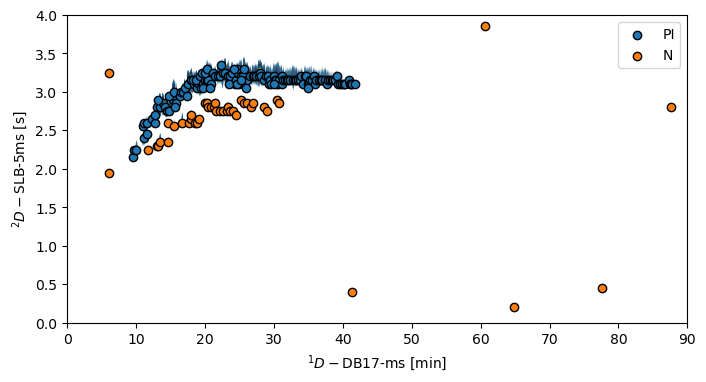

In [7]:
# scatter plot with raw data

fig, ax = plt.subplots(figsize=(8, 4))

xmin = 0
xmax = 90
ymin = 0
ymax = 4

c2c.plot2d(fig, ax,
           raw_data.rt, raw_data.bpc,
           mod_time=4, shift= 1, solvent_cut= 0,
           color_range=(8, 80), axis_labels=('DB17-ms', 'SLB-5ms'),
           cbar=False)

for cl in fragments_shimadzu.keys():
    sub_df = results_df[results_df['Class'] == cl]

    if len(sub_df) > 0 :
        ax.scatter(sub_df['RT 1d (min)'], sub_df['RT 2d (s)'], label=cl, edgecolors='black')

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.legend()

plt.show()

In [8]:
# export data frame
results_df.to_csv('C2C-005_results.csv', sep=',', index=False)